# 05 · Feature engineering
**Input:** `data/processed/master_converted.csv.gz` (from `04_conversion`) · **Code:** `src/features.py` · **Outputs:** `logs/features_summary.csv`, `figures/05_features_*.png`

What this notebook does, following the rubric:
1. **Encoding** of the target and of categorical columns
2. **Extraction / creation:** TF-IDF character n-grams for the classical models, character sequences for the neural model, two numeric features
3. **Transformation / scaling:** sublinear TF, L2 normalization, log transform and standardization of length
4. **Selection:** frequency filters, then chi-square selection fitted on training labels only
5. **Verification** of the resulting features, including how many Arabic test n-grams the features actually "see" with and without the conversion
6. **The final feature set and why**

No model is trained here (models are the next phase). Every builder is **fitted on training rows only** and then applied to the test rows.

In [1]:
# Works both locally (repo root or notebooks/) and in Colab after cloning the repo.
import os, sys
from pathlib import Path
if Path("notebooks").is_dir():
    ROOT = Path(".").resolve()
elif Path("../notebooks").is_dir():
    ROOT = Path("..").resolve()
else:  # Colab: the repository is cloned into /content first
    ROOT = Path("/content/tunisian-sentiment")
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
print("Repo root found:", ROOT.name)

Repo root found: tunisian-sentiment


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from src.features import TFIDF_PARAMS, build_tfidf, build_numeric, combine, build_char_sequences
from src.plot_style import setup, COLORS, INK, MUTED, subtitle

setup()
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
df = pd.read_csv(ROOT / "data/processed/master_converted.csv.gz", keep_default_na=False)
print(df.shape); df[["script", "text", "text_norm", "text_conv"]].head(3)

(111531, 13)


,script,text,text_norm,text_conv
0,arabizi,7yeti ca ya slouma,7yeti ca ya slouma,7t c slm
1,arabizi,rabi yehdik aka chenajmou n9oulo,rabi yehdik aka chenajmou n9oulo,rb hdk k chnjm n9l
2,arabizi,amazing like usual,amazing like usual,mzng lk sl


## 1. Encoding
- **Target:** `label` → `y` = 1 for positive, 0 for negative.
- **Script:** **not** used as a feature. The chi-square test (EDA) showed script and sentiment are linked, so a model given the script could partly guess sentiment from it instead of from the words. Script is only used to choose training and test rows and to report results per script.
- **Source and split:** bookkeeping columns, never features.

In [3]:
df["y"] = (df.label == "pos").astype(int)
print(pd.crosstab(df.label, df.y))

y          0      1
label              
neg    51048      0
pos        0  60483


## 2. The setting used here: k = 0 (our main experiment)
- **Train:** all Arabizi training comments (TUNIZI + TSAC Arabizi train): the model sees **no** Arabic script.
- **Test:** the Arabic-script TSAC test comments (1,482).

The other settings of the learning curve (k = 100, 500, 1,000, all) only add k Arabic-script training comments; the same builders are refitted on each training set.

In [4]:
train = df[(df.split == "train") & (df.script == "arabizi")].reset_index(drop=True)
test = df[(df.split == "test") & (df.script == "arabic")].reset_index(drop=True)
ar_pool = df[(df.split == "train") & (df.script == "arabic")]
print(f"train (Arabizi): {len(train):,} | test (Arabic): {len(test):,} | Arabic pool for k > 0: {len(ar_pool):,}")
assert not set(train.id) & set(test.id)

train (Arabizi): 102,836 | test (Arabic): 1,482 | Arabic pool for k > 0: 5,506


## 3. Extraction: TF-IDF on character n-grams
**Why character n-grams and not words:** half the comments have 6 words or fewer, Arabizi has no fixed spelling (3aychek / 3ichek / aichek) and both scripts are full of elongations and typos. Pieces of 2 to 5 characters still match when whole words don't. `char_wb` keeps n-grams inside word boundaries, so they don't glue the end of one word to the start of the next.

**Transformation built into TF-IDF:** `sublinear_tf` replaces a count by 1 + log(count), so a stretched or repeated piece doesn't dominate a comment; rows are **L2-normalized**, so long and short comments are comparable.

Two conditions, identical settings: **without mapping** (`text_norm`) and **with mapping** (`text_conv`).

In [5]:
print("TF-IDF settings:", {k: v for k, v in TFIDF_PARAMS.items() if k != "dtype"})
feats = {}
for cond, col in [("without mapping", "text_norm"), ("with mapping", "text_conv")]:
    X_tr, X_te, vec, _ = build_tfidf(train[col], test[col])
    feats[cond] = dict(col=col, X_tr=X_tr, X_te=X_te, vec=vec)
    print(f"{cond:16} train {X_tr.shape}  test {X_te.shape}  "
          f"density {X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1]):.5f}")

TF-IDF settings: {'analyzer': 'char_wb', 'ngram_range': (2, 5), 'min_df': 5, 'max_df': 0.9, 'sublinear_tf': True, 'lowercase': False}


without mapping  train (102836, 114684)  test (1482, 114684)  density 0.00119


with mapping     train (102836, 34995)  test (1482, 34995)  density 0.00192


## 4. Selection, step 1: frequency filters
`min_df = 5` drops n-grams seen in fewer than 5 training comments (mostly typos and one-off spellings that can't generalize); `max_df = 0.9` drops n-grams present in over 90% of comments (they carry no information). How much this removes:

In [6]:
rows = []
for cond, f in feats.items():
    full = build_tfidf(train[f["col"]], test[f["col"]], min_df=1, max_df=1.0)[2]
    rows.append({"condition": cond, "n-grams before filters": len(full.vocabulary_),
                 "after min_df=5, max_df=0.9": len(f["vec"].vocabulary_)})
filt = pd.DataFrame(rows)
filt["kept (%)"] = (100 * filt.iloc[:, 2] / filt.iloc[:, 1]).round(1)
filt

,condition,n-grams before filters,"after min_df=5, max_df=0.9",kept (%)
0,without mapping,373511,114684,30.7
1,with mapping,101107,34995,34.6


## 5. Verification: does the model "see" the Arabic test comments?
The features are learned from Arabizi only. For each Arabic test comment we count how many of its features are non-zero, i.e. how many of its character n-grams exist in the Arabizi-trained vocabulary. A comment with **zero** known n-grams is invisible to the model.

      condition  known n-grams per comment (median)  comments with zero known n-grams (%)  comments with 10+ known n-grams (%)
without mapping                                 0.0                                  71.1                                  2.1
   with mapping                                56.0                                   0.0                                 98.9


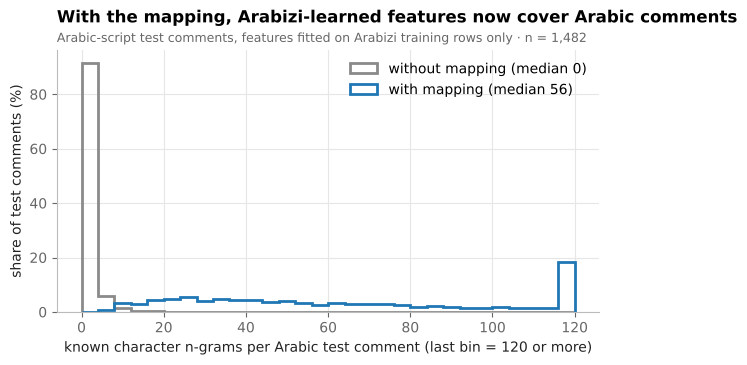

In [7]:
ver = []
for cond, f in feats.items():
    nz = np.diff(f["X_te"].indptr)                      # non-zero features per test comment
    ver.append({"condition": cond,
                "known n-grams per comment (median)": float(np.median(nz)),
                "comments with zero known n-grams (%)": round(100 * (nz == 0).mean(), 1),
                "comments with 10+ known n-grams (%)": round(100 * (nz >= 10).mean(), 1)})
    f["nz"] = nz
ver = pd.DataFrame(ver); print(ver.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.arange(0, 121, 4)
for cond, color in [("without mapping", "#8a8a8a"), ("with mapping", COLORS["arabic"])]:
    nz = feats[cond]["nz"]
    ax.hist(np.clip(nz, 0, 120), bins=bins, weights=np.full(len(nz), 100 / len(nz)),
            histtype="step", lw=2, color=color, label=f"{cond} (median {np.median(nz):.0f})")
ax.set_xlabel("known character n-grams per Arabic test comment (last bin = 120 or more)")
ax.set_ylabel("share of test comments (%)")
ax.set_title("With the mapping, Arabizi-learned features now cover Arabic comments")
subtitle(ax, f"Arabic-script test comments, features fitted on Arabizi training rows only · n = {len(test):,}")
ax.legend()
fig.savefig(FIG / "05_features_test_coverage.png"); plt.show()

**Result:** without the mapping, **71% of Arabic test comments share no n-gram at all** with the Arabizi-trained features (median: 0 known n-grams per comment); the few matches come from Latin words, digits or punctuation inside Arabic comments. **With the mapping, every test comment has known n-grams** (median 56; 99% have 10 or more).

**Why this matters:** this is the feature-level evidence for our research question. Without the mapping, a model trained on Arabizi is blind to most Arabic-script comments; with it, the same features cover them. Whether the overlap carries the right *sentiment* signal is what the modeling phase will measure.

## 6. Selection, step 2: chi-square
Even after the frequency filters there are hundreds of thousands of n-grams, most unrelated to sentiment. The **chi-square** score measures how strongly each n-gram's presence depends on the label (computed on **training** labels only). We keep the best **k = 20,000** in **both** conditions: the same budget keeps the comparison fair (the vocabulary with mapping is smaller, about 35,000 n-grams, because removing vowels merges many spelling variants). Below: the 10 strongest selected n-grams for each class (with mapping). Spaces mark word edges.

In [8]:
K = 20_000
for cond, f in feats.items():
    X_tr_s, X_te_s, vec, sel = build_tfidf(train[f["col"]], test[f["col"]], k_best=K, train_labels=train.y)
    assert sel is not None, "k must be smaller than the vocabulary"
    f.update(X_tr_sel=X_tr_s, X_te_sel=X_te_s, sel=sel)
    kept_nz = np.diff(X_te_s.indptr)
    print(f"{cond:16} {len(vec.vocabulary_):,} -> {X_tr_s.shape[1]:,} n-grams | "
          f"Arabic test comments with zero selected n-grams: {100 * (kept_nz == 0).mean():.1f}%")

f = feats["with mapping"]; names = f["vec"].get_feature_names_out()
scores = pd.Series(f["sel"].scores_, index=names).dropna()
mean_pos = np.asarray(f["X_tr"][train.y.values == 1].mean(axis=0)).ravel()
mean_neg = np.asarray(f["X_tr"][train.y.values == 0].mean(axis=0)).ravel()
lean = pd.Series(np.where(mean_pos > mean_neg, "positive", "negative"), index=names)
def top_for(cls, n=10):
    t = scores[lean[scores.index] == cls].sort_values(ascending=False).head(n)
    return pd.DataFrame({f"{cls} n-gram": [repr(x) for x in t.index], "chi2": t.values.round(0).astype(int)}).reset_index(drop=True)
pd.concat([top_for("positive"), top_for("negative")], axis=1)

without mapping  114,684 -> 20,000 n-grams | Arabic test comments with zero selected n-grams: 89.3%


with mapping     34,995 -> 20,000 n-grams | Arabic test comments with zero selected n-grams: 0.0%


,positive n-gram,chi2,negative n-gram,chi2
0,'brv',658,' mst ',249
1,' brv',656,' mst',246
2,'brv ',653,'mst ',236
3,' brv ',652,'mst',234
4,'rv ',628,' nk',218
5,'rv',610,' ms',212
6,'v ',589,' ml ',204
7,' rb ',549,'ch ',204
8,' rb',506,'tfh ',202
9,'m3lm ',460,' tfh ',199


**Result:** the selection keeps 20,000 n-grams in each condition. After selection, **89% of Arabic test comments have no selected n-gram without the mapping, against 0% with it.**

The strongest n-grams are readable even without vowels: `brv` = bravo, `m3lm` = m3allem ("master", praise), `rb` = rabi ("God", as in "rabi m3ak"), and on the negative side insults and contempt. Because selection uses only training labels, it cannot leak test information.

## 7. Created numeric features: transformation and scaling
- **Length:** `n_chars` and `n_words` are 95% correlated (EDA), so only one is kept. Length is very right-skewed, so it is **log-transformed** (`log(1 + n_chars)`) and then **standardized** (mean 0, standard deviation 1, scaler fitted on training rows).
- **has_elongation:** normalization collapses stretched letters (bravooooo → bravo), so this 0/1 flag keeps the information that the writer stretched a word.
- **Not kept:** `n_words` (duplicate of length), `has_arabizi_digits` (a stand-in for script), `has_emoji` (TUNIZI has none, so the model could not learn it from training data).

In [9]:
num_tr, num_te, scaler = build_numeric(train, test)
print(f"skewness of n_chars: raw {stats.skew(train.n_chars):.2f} -> log(1 + n_chars) {stats.skew(np.log1p(train.n_chars)):.2f}")
print(f"after scaling, train: mean {num_tr[:, 0].mean():.3f}, std {num_tr[:, 0].std():.3f} | test: mean {num_te[:, 0].mean():.3f}")
pd.DataFrame(num_tr, columns=["log_len_scaled", "has_elongation"]).describe().round(3)

skewness of n_chars: raw 10.45 -> log(1 + n_chars) 0.57
after scaling, train: mean 0.000, std 1.000 | test: mean -0.115


,log_len_scaled,has_elongation
count,102836.000,102836.000
mean,0.000,0.181
std,1.000,0.385
min,-3.633,0.000
25%,-0.757,0.000
50%,-0.132,0.000
75%,0.625,0.000
max,6.214,1.000


## 8. Final matrix for the classical models

In [10]:
for cond, f in feats.items():
    f["X_tr_final"], f["X_te_final"] = combine(f["X_tr_sel"], num_tr), combine(f["X_te_sel"], num_te)
    print(f"{cond:16} train {f['X_tr_final'].shape} | test {f['X_te_final'].shape} | "
          f"{f['X_tr_final'].data.nbytes / 1e6:.0f} MB of non-zero values")
assert feats["with mapping"]["X_tr_final"].shape[0] == len(train) and feats["with mapping"]["X_te_final"].shape[0] == len(test)

without mapping  train (102836, 20002) | test (1482, 20002) | 77 MB of non-zero values
with mapping     train (102836, 20002) | test (1482, 20002) | 50 MB of non-zero values


## 9. Character sequences for the CNN/BiLSTM
The neural model reads characters one by one, so each comment becomes a fixed-length sequence of character ids (0 = padding, 1 = unknown character). The length is the **95th percentile of training comments** for each condition, so 95% of comments fit whole; converted text is shorter because the vowels are gone.

In [11]:
seq_rows = []
for cond, f in feats.items():
    max_len = int(np.percentile(train[f["col"]].str.len(), 95))
    S_tr, S_te, index = build_char_sequences(train[f["col"]], test[f["col"]], max_len)
    unk = (S_te == 1).sum() / max((S_te > 0).sum(), 1)
    seq_rows.append({"condition": cond, "max_len (95th pct)": max_len, "char vocabulary": len(index),
                     "train shape": S_tr.shape, "test chars unknown (%)": round(100 * unk, 2),
                     "test comments cut (%)": round(100 * (test[f["col"]].str.len() > max_len).mean(), 1)})
seqs = pd.DataFrame(seq_rows); seqs

,condition,max_len (95th pct),char vocabulary,train shape,test chars unknown (%),test comments cut (%)
0,without mapping,171,184,"(102836, 171)",31.45,4.1
1,with mapping,103,165,"(102836, 103)",0.30,5.8


**Result:** without the mapping, **31% of the characters in Arabic test comments are unknown** to a network trained on Arabizi (the Arabic letters never appear in training); with the mapping, only **0.3%** are unknown. Converted comments are also shorter (103 vs 171 positions), because vowels are removed.

## 10. Final feature set

In [12]:
summary = pd.DataFrame([
    {"feature": "TF-IDF char 2-5-grams, chi-square top 20,000", "for": "TF-IDF + LR, Naive Bayes",
     "built from": "text_norm or text_conv", "why": "robust to spelling variation; carries the sentiment words"},
    {"feature": "log(1 + n_chars), standardized", "for": "TF-IDF + LR",
     "built from": "n_chars", "why": "length weakly linked to sentiment (r = -0.18); log removes the skew"},
    {"feature": "has_elongation (0/1)", "for": "TF-IDF + LR",
     "built from": "text", "why": "keeps the stretching signal lost by normalization"},
    {"feature": "character id sequences", "for": "CNN / BiLSTM",
     "built from": "text_norm or text_conv", "why": "lets the network learn its own character patterns"},
])
for cond, f in feats.items():
    summary[f"size ({cond})"] = [f"{f['X_tr_sel'].shape[1]:,} columns", "1 column", "1 column",
                                 f"{seqs.set_index('condition').loc[cond, 'max_len (95th pct)']} positions"]
summary.to_csv(ROOT / "logs/features_summary.csv", index=False, encoding="utf-8")
summary

,feature,for,built from,why,size (without mapping),size (with mapping)
0,"TF-IDF char 2-5-grams, chi-square top 20,000","TF-IDF + LR, Naive Bayes",text_norm or text_conv,robust to spelling variation; carries the sent...,"20,000 columns","20,000 columns"
1,"log(1 + n_chars), standardized",TF-IDF + LR,n_chars,length weakly linked to sentiment (r = -0.18);...,1 column,1 column
2,has_elongation (0/1),TF-IDF + LR,text,keeps the stretching signal lost by normalization,1 column,1 column
3,character id sequences,CNN / BiLSTM,text_norm or text_conv,lets the network learn its own character patterns,171 positions,103 positions


**Excluded on purpose:** `script` and `has_arabizi_digits` (they would let a model use the script-label shortcut), `has_emoji` (absent from TUNIZI), `n_words` (duplicate of `n_chars`).

**Note for the modeling phase:** Naive Bayes (multinomial) needs non-negative inputs, so it uses only the TF-IDF block, not the standardized length column.